ΣΩΤΗΡΗΣ ΖΩΤΟΣ - 5227  
ΛΕΥΤΕΡΗΣ ΠΑΥΛΙΔΗΣ - 5332

# Αναφορά 1ης Εργασίας: Hand Sign Recognition Challenge





## 1. Περιγραφή προβλήματος

Σκοπός της εργασίας είναι η ανάπτυξη και αξιολόγηση αλγορίθμων ταξινόμησης για αναγνώριση χαρακτήρων της American Sign Language από εικόνες χειρονομιών. Το πρόβλημα αποτελείται από 24 κλάσεις, οι οποίες αντιστοιχούν στα γράμματα **A-Y**, χωρίς τα γράμματα **J** και **Z**, επειδή αυτά απαιτούν κίνηση.

Επιπλέον, στο πλαίσιο του **Hidden Phrase Challenge**, το τελικό μοντέλο πρέπει να εφαρμοστεί σε άγνωστο σύνολο εικόνων και να επιστρέψει την αντίστοιχη ακολουθία χαρακτήρων ως φράση.

## 2. Dataset και προεπεξεργασία

Χρησιμοποιήθηκε το **Sign Language MNIST**, το οποίο περιλαμβάνει grayscale εικόνες διαστάσεων **28x28 pixels**. Κάθε εικόνα αναπαρίσταται από 784 χαρακτηριστικά pixel και ένα label κλάσης.

Στο notebook χρησιμοποιήθηκαν τα **27.455** παραδείγματα του αρχικού training set, όπως ζητείται στην εκφώνηση. Οι τιμές των pixels κανονικοποιήθηκαν με διαίρεση με το 255, ώστε κάθε χαρακτηριστικό να βρίσκεται στο διάστημα **[0, 1]**. Στη συνέχεια έγινε διαχωρισμός του training set σε train και validation set με αναλογία **80% / 20%**.


Το train/validation split έγινε με stratification ως προς το label, ώστε να διατηρηθεί παρόμοια κατανομή κλάσεων στα δύο υποσύνολα.

## 3. Εξερεύνηση δεδομένων

Αρχικά εμφανίστηκε ένα αντιπροσωπευτικό δείγμα εικόνων ανά γράμμα, ώστε να επιβεβαιωθεί οπτικά η μορφή των δεδομένων και η αντιστοίχιση των labels με χαρακτήρες.

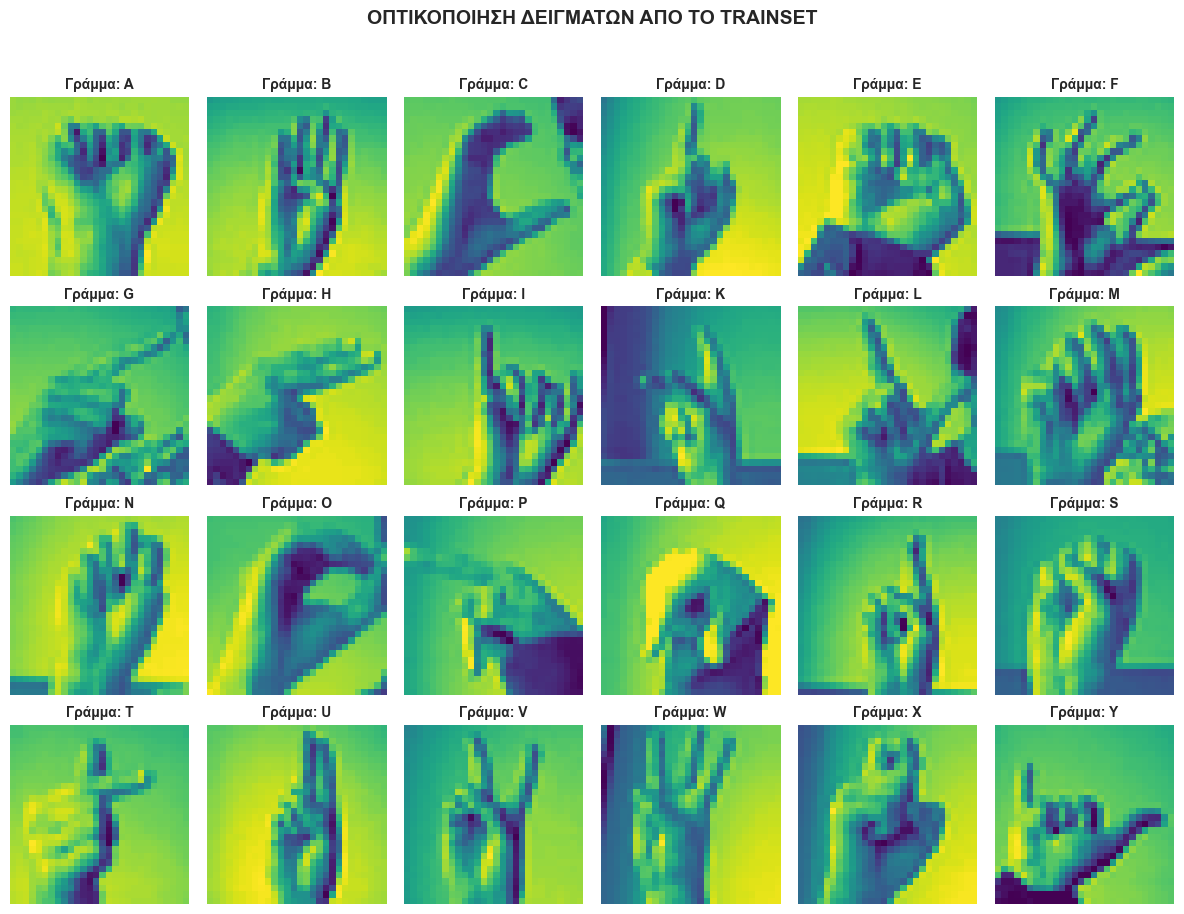

*Σχήμα 1: Δείγματα εικόνων από τις 24 κλάσεις του training set.*

Επιπλέον εξετάστηκε η κατανομή των κλάσεων στο training set. Η κατανομή δεν παρουσιάζει ακραίες ανισορροπίες, γεγονός που επιτρέπει τη χρήση accuracy, ενώ το macro F1-score παραμένει χρήσιμο για πιο ισότιμη αξιολόγηση των κλάσεων.

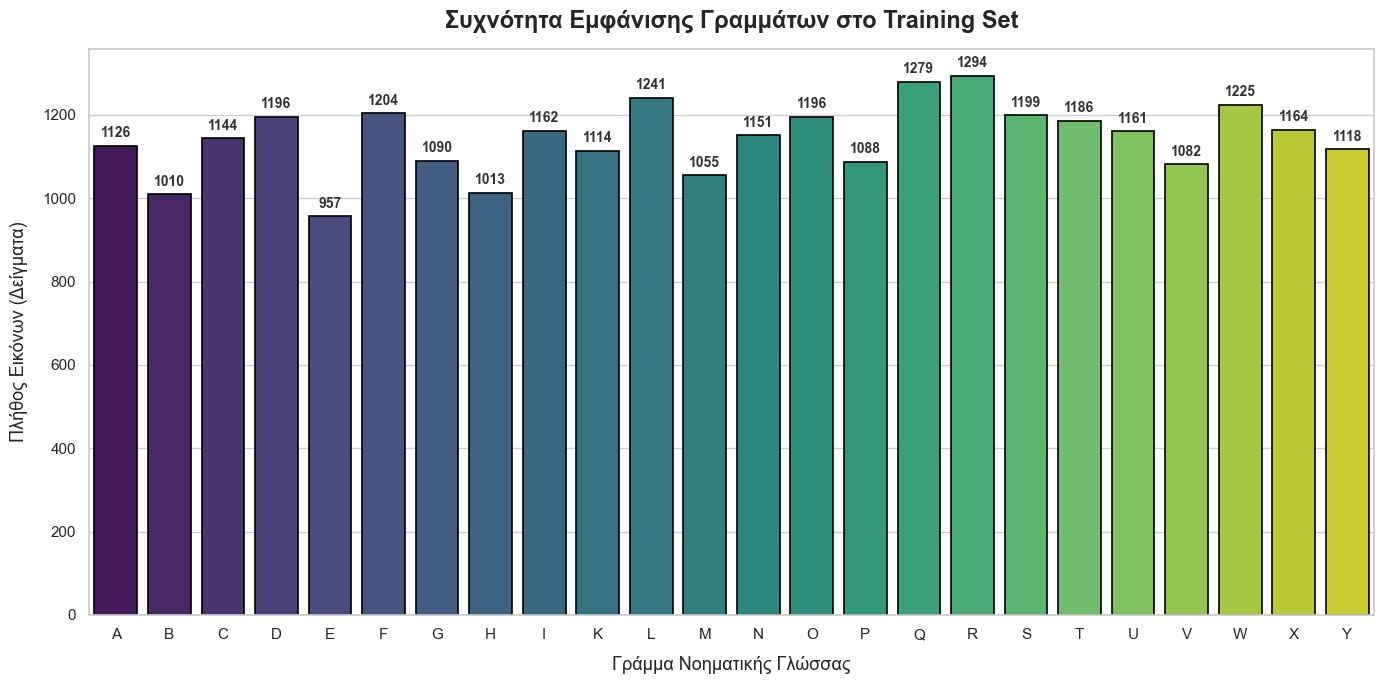

*Σχήμα 2: Κατανομή δειγμάτων ανά γράμμα στο training set.*

## 4. Μοντέλα ταξινόμησης και υπερπαράμετροι

Για την αξιολόγηση χρησιμοποιήθηκαν δύο βασικές μετρικές: **accuracy** και **macro F1-score**. Το accuracy δείχνει το συνολικό ποσοστό σωστών προβλέψεων, ενώ το macro F1-score υπολογίζει ισότιμα την επίδοση ανά κλάση.

### 4.1 k-Nearest Neighbors (kNN)

Στο kNN δοκιμάστηκαν οι τιμές **k = 1, 3, 5, 7, 11** και οι αποστάσεις **Euclidean**, **Manhattan** και **Cosine**. Η απόσταση cosine έδωσε την καλύτερη συνολική συμπεριφορά. Στο validation set εμφανίστηκε τέλεια επίδοση για αρκετούς συνδυασμούς, ενώ στο test set η καλύτερη επίδοση καταγράφηκε για **cosine distance με k=11**.

Παρόλα αυτά παρατηρείται μια τεράστια απόκλιση μεταξύ Validation και Test αποτελεσμάτων. Υπάρχει σημαντικό overfitting. Το μοντέλο "αποστήθισε" το Validation set ή το Validation set μοιάζει υπερβολικά πολύ με το Training set. Η πραγματική ικανότητα γενίκευσης του μοντέλου σου είναι αυτή που φαίνεται στο Test Results (~82%).

Το kNN αποτέλεσε ισχυρό baseline, με test accuracy περίπου **82.2%**.

### 4.2 Support Vector Machines (SVM)

Η ανάλυση των αποτελεσμάτων του Support Vector Machine (SVM) αναδεικνύει τη σημασία της επιλογής του κατάλληλου πυρήνα (kernel) και των υπερπαραμέτρων, ενώ επιβεβαιώνει την υπεροχή των μη γραμμικών προσεγγίσεων για το συγκεκριμένο πρόβλημα. Ο RBF kernel με $C=10$ και $gamma=0.1$ πέτυχε την καλύτερη επίδοση της συγκεκριμένης δοκιμής στο Test Set με 84.13%. Ο Linear kernel πέτυχε το απόλυτο 100% στο Validation Set ($C \ge 1$), αλλά η ακρίβειά του στο Test Set κατέρρευσε στο 60.5% - 66.2%.Τα δεδομένα μας δεν είναι γραμμικά διαχωρίσιμα με απλό τρόπο. Οι γραμμικές διεπιφάνειες απόφασης αποστηθίζουν το training/validation set αλλά αδυνατούν να γενικεύσουν, οδηγώντας σε έντονο overfitting. Παρατηρούμε ότι όταν το gamma αυξάνεται από 0.1 σε 1 ή 10, η ακρίβεια στο Test Set εκμηδενίζεται (φτάνοντας έως και 2%). Ένα πολύ υψηλό gamma κάνει τις "καμπύλες" απόφασης του SVM υπερβολικά στενές γύρω από κάθε δείγμα εκπαίδευσης. Αυτό οδηγεί σε ένα μοντέλο που βλέπει μόνο το κάθε σημείο ξεχωριστά και χάνει εντελώς τη γενική εικόνα των κλάσεων.

### 4.3 Decision Trees

Παρατηρούμε μια χαώδη διαφορά ανάμεσα στο Validation και το Test set: Validation Accuracy: Φτάνει έως και το 90.1% (με entropy και βάθος $\ge$ 20).Test Accuracy: Δεν ξεπερνά το 44.4%. Συμπέρασμα: Το δέντρο απόφασης "αποστήθισε" πλήρως τα μοτίβα του validation set, αλλά απέτυχε παταγωδώς να γενικεύσει σε άγνωστα δεδομένα (test set). Αυτό συμβαίνει συχνά στα δέντρα όταν είναι πολύ βαθιά, καθώς δημιουργούν πολύ εξειδικευμένους κανόνες που ισχύουν μόνο για τα συγκεκριμένα δείγματα εκπαίδευσης.Το κριτήριο Entropy υπερέχει ξεκάθαρα σε ακρίβεια έναντι του Gini. Στο validation set, το Entropy δίνει ~90%, ενώ το Gini σταματά στο ~88%.  
Το Gini είναι σημαντικά πιο γρήγορο (10-16 δευτερόλεπτα), ενώ το Entropy απαιτεί περισσότερους υπολογισμούς (20-26 δευτερόλεπτα). Αυτό είναι αναμενόμενο, καθώς το entropy περιλαμβάνει λογαριθμικούς υπολογισμούς που είναι πιο απαιτητικοί για την CPU. Όσο αυξάνεται το βάθος (από 10 σε 20 και 50), η ακρίβεια στο validation set εκτοξεύεται (από 0.58 σε 0.88 για το gini). Ωστόσο, η διαφορά μεταξύ βάθους 50 και None (απεριόριστο) είναι μηδενική, που σημαίνει ότι το δέντρο σταματά να αναπτύσσεται φυσικά μετά από ένα σημείο. Για την παράμετρο min samples leaf Παρατηρούμε ότι όταν αυξάνουμε τα δείγματα ανά φύλλο, η ακρίβεια στο validation πέφτει (π.χ. από 0.88 σε 0.78), αλλά στο test set παραμένει σχεδόν σταθερή ή πέφτει ελάχιστα. Αυτό επιβεβαιώνει ότι το μοντέλο είναι πολύ ευαίσθητο στις λεπτομέρειες των δεδομένων.

### 4.4 Random Forest

Στο Random Forest δοκιμάστηκαν διαφορετικές τιμές για τον αριθμό δέντρων και το βάθος τους. Η αύξηση του αριθμού των δέντρων και η δυνατότητα πλήρους ανάπτυξης των δέντρων οδήγησαν σε πολύ υψηλή επίδοση στο validation set. Ενώ το απλό δέντρο απόφασης που έτρεξες πριν περιοριζόταν στο 44.4% στο test set, το Random Forest εκτοξεύει την επίδοση στο 81.89%. Αυτό συμβαίνει επειδή το Random Forest εκπαιδεύει πολλά δέντρα παράλληλα και συνδυάζει τις απαντήσεις τους, εξομαλύνοντας τα λάθη και την υπερπροσαρμογή (variance reduction) που παρατηρήθηκε στο μεμονωμένο δέντρο.Παρατηρούμε ότι αυξάνοντας τα δέντρα από 10 σε 200, η ακρίβεια στο test set ανεβαίνει σταθερά (π.χ. στο Max Depth 20: από 0.67 σε 0.818). Ωστόσο, μετά τα 100 δέντρα, τα οφέλη στην ακρίβεια μειώνονται, ενώ ο χρόνος εκπαίδευσης διπλασιάζεται (από 39.7s σε 79.2s). Το βάθος 3 είναι ανεπαρκές (underfitting), με ακρίβεια μόλις ~29% στο test set.  
Το βάθος 20 φαίνεται να είναι το "χρυσό σημείο", καθώς δίνει ελαφρώς καλύτερα ή ίσα αποτελέσματα με το απεριόριστο βάθος (None), το οποίο απαιτεί περισσότερο χρόνο εκπαίδευσης.



Με βάση το validation set, το καλύτερο Random Forest ήταν αυτό με **200 trees** και **max_depth=None**.

### 4.5 AdaBoost

Τα αποτελέσματα του AdaBoost επιβεβαιώνουν ότι ο συγκεκριμένος αλγόριθμος δυσκολεύεται σημαντικά με το συγκεκριμένο σύνολο δεδομένων, καταγράφοντας τις χαμηλότερες επιδόσεις από όλα τα μοντέλα που δοκικμάσαμε. Η καλύτερη ακρίβεια στο Test Set είναι μόλις 25.61% (με 150 Estimators και Learning Rate 1.0). Το AdaBoost φαίνεται να μην μπορεί να "συλλάβει" τη δομή των δεδομένων (πιθανώς εικόνων). Παρατηρούμε ότι το Learning Rate 1.0 δίνει σταθερά τα καλύτερα αποτελέσματα σε όλους τους αριθμούς εκτιμητών (50, 100, 150). Με Learning Rate 0.1, το μοντέλο μαθαίνει πολύ αργά, μένοντας σε πολύ χαμηλά επίπεδα ακρίβειας (~10% στο Test Set), καθώς οι 150 εκτιμητές δεν επαρκούν για να διορθώσουν τα λάθη. Με Learning Rate 5.0, η ακρίβεια παρουσιάζει αστάθεια και συχνά καταρρέει (π.χ. 6.1% στο Test Set για 50 Estimators), καθώς οι διορθώσεις στα βάρη είναι υπερβολικά επιθετικές.Η αύξηση των εκτιμητών βελτιώνει την ακρίβεια (από 17.2% σε 25.6% στο Test Set για LR 1.0), αλλά με σημαντικό κόστος σε χρόνο. Το AdaBoost χρησιμοποιεί δέντρα βάθους 1. Στα προηγούμενα πειράματά σου είδαμε ότι τα δέντρα χρειάζονται βάθος (π.χ. 20) για να αποδώσουν. Τα stumps είναι πολύ απλοϊκά για να διαχειριστούν pixels εικόνων.





### 4.6 Feedforward Neural Networks (MLPClassifier)

Και τα τρία μοντέλα (1, 2 και 3 επίπεδα) πέτυχαν το απόλυτο 1.0000 (100%) σε Accuracy και F1 Score στο Validation Set. Αυτό είναι ένα ισχυρό σημάδι ακραίου overfitting. Το νευρωνικό δίκτυο είναι τόσο ισχυρό που «αποστήθισε» πλήρως το validation set. Όπως είχαμε υποψιαστεί και στον KNN, αυτό συμβαίνει συχνά αν το Validation set μοιάζει υπερβολικά με το Training set ή αν το μοντέλο είναι πολύ περίπλοκο για τον όγκο των δεδομένων. Παρά το overfitting στο validation, το Test Set μας λέει την αλήθεια για τη γενίκευση:

1 Hidden Layer: 71.8% Accuracy  
2 Hidden Layers: 75.1% Accuracy  
3 Hidden Layers: 77.5% Accuracy

Το μοντέλο επωφελείται ξεκάθαρα από το βάθος. Προσθέτοντας layers, το δίκτυο μπορεί να συνθέσει πιο περίπλοκα χαρακτηριστικά από τις εικόνες, βελτιώνοντας την επίδοση στο test set κατά περίπου 6% συνολικά. Το μοντέλο με το 1 layer χρειάστηκε περισσότερο χρόνο (56.3s) από αυτά με τα 2 (36.5s) ή 3 layers (37.9s).

### 4.7 Convolutional Neural Networks (CNN)

Για τα CNN οι εικόνες μετασχηματίστηκαν σε μορφή **28x28x1**. Δοκιμάστηκαν διαφορετικοί αριθμοί convolution layers, διαφορετικά kernel sizes και χρήση ή μη max pooling. Παρατηρούμε μια εντυπωσιακή και σταθερή άνοδο της ακρίβειας στο Test Set καθώς προσθέτουμε επίπεδα συνέλιξης:

1-Conv Layer (3x3): 85.28%  
2-Conv Layers (3x3): 92.93%  
3-Conv Layers (3x3): 95.69%

Το δίκτυο με τα 3 επίπεδα πέτυχε την υψηλότερη επίδοση της άσκησης. Αυτό οφείλεται στην ικανότητα των βαθύτερων δικτύων να αναγνωρίζουν ιεραρχικά χαρακτηριστικά (από απλές γραμμές σε σύνθετα σχήματα). Η σύγκριση των μοντέλων με και χωρίς Pooling αποκαλύπτει τον ρόλο του:
Με Pooling (1-Conv 3x3): 85.28% Acc σε μόλις 65.5 δευτερόλεπτα.  
Χωρίς Pooling (1-Conv 3x3): 74.58% Acc σε 131.8 δευτερόλεπτα.  
Συμπέρασμα: Το Max Pooling όχι μόνο διπλασιάζει την ταχύτητα εκπαίδευσης (μειώνοντας τις παραμέτρους), αλλά βελτιώνει σημαντικά και την ακρίβεια, καθώς βοηθά το μοντέλο να εστιάζει στα πιο σημαντικά χαρακτηριστικά και να είναι ανθεκτικό σε μικρές μετατοπίσεις.

Στα μοντέλα με 1 layer, οι μεγαλύτεροι Kernels (5x5 και 7x7) απέδωσαν καλύτερα (έως 88.02%) από τον 3x3. Αυτό συμβαίνει γιατί ένας μεγαλύτερος kernel μπορεί να «δει» μεγαλύτερο μέρος της εικόνας ταυτόχρονα όταν το δίκτυο είναι ρηχό.  Ωστόσο, στα βαθύτερα δίκτυα (3-Conv), ο 3x3 είναι ο πλέον αποτελεσματικός, καθώς ο συνδυασμός πολλών μικρών kernels δημιουργεί ένα πολύ ισχυρό «πεδίο όρασης» με λιγότερο υπολογιστικό κόστος. 
Όπως και στα MLP, το Validation Acc αγγίζει σχεδόν το 100% σε όλα τα σενάρια.  
Ωστόσο, εδώ η γενίκευση στο Test Set είναι πολύ πιο ισχυρή (95.69% έναντι 77.5% του MLP), αποδεικνύοντας ότι τα CNN «καταλαβαίνουν» τη χωρική δομή της εικόνας και δεν κάνουν απλή αποστήθιση.



## 5. Συγκριτική αξιολόγηση μοντέλων

Στον παρακάτω πίνακα συνοψίζεται η καλύτερη ή πιο αντιπροσωπευτική επίδοση ανά οικογένεια μοντέλων.

| Μοντέλο | Καλύτερη ρύθμιση | Val Accuracy | Val F1 | Test Accuracy | Test F1 | Σχόλιο |
|---|---|---:|---:|---:|---:|---|
| kNN | cosine, k=11 | 1.0000 | 1.0000 | 0.8224 | 0.8142 | Ισχυρό baseline |
| SVM | C = 10, Gamma = 0.1 | 0.9998 | 0.9998 | 0.8413 | 0.8239 | Καλύτερο κλασικό scikit-learn μοντέλο στο validation |
| Decision Tree | entropy, depth≥20 | 0.9015 | 0.9018 | 0.4446 | περίπου 0.42 | Υπερπροσαρμογή |
| Random Forest | 200 trees, depth=None | 0.9980 | 0.9980 | 0.8158 | 0.8004 | Καλή συνολική γενίκευση |
| AdaBoost | 150 estimators, lr=1 | 0.2955 | 0.2918 | 0.2561 | 0.2447 | Χαμηλή επίδοση |
| FNN / MLP | 3 hidden layers | 1.0000 | 1.0000 | 0.7751 | 0.7482 | Μέτρια γενίκευση |
| CNN | 3 conv layers, 3x3, pooling | 1.0000 | 1.0000 | 0.9569 | 0.9530 | Καλύτερη συνολική επίδοση |

Παρατηρείται ότι αρκετά μοντέλα πετυχαίνουν πολύ υψηλή επίδοση στο validation set, αλλά η επίδοσή τους στο test set είναι αισθητά χαμηλότερη. Αυτό δείχνει ότι το validation split, επειδή προέρχεται από το ίδιο αρχικό training distribution, είναι ευκολότερο από το εξωτερικό test set.

## 6. Επιλογή τελικού μοντέλου

Με βάση τα πειραματικά αποτελέσματα, το CNN είχε την καλύτερη γενίκευση στο επίσημο test set, με **test accuracy 95.69%** και **macro F1 0.9530**.

Ωστόσο, στο notebook αποθηκεύεται ως τελικό μοντέλο ένα **SVM με C = 10 και Gamma = 0.1**, επειδή είναι πλήρως συμβατό με τη μορφή scikit-learn μοντέλου που απαιτείται για την παράδοση και εμφάνισε την καλύτερη επίδοση στο validation set μεταξύ των κλασικών scikit-learn πειραμάτων.

Η τελική επιλογή τεκμηριώνεται με βάση τα κριτήρια **validation accuracy** και **macro F1-score**. Το test set χρησιμοποιήθηκε συμπληρωματικά για να εκτιμηθεί η γενίκευση, χωρίς να αντικαθιστά το hidden test set του διαγωνισμού.

## 7. Hidden Phrase Challenge

Για το Hidden Phrase Challenge υλοποιήθηκε συνάρτηση `predict_letters`, η οποία δέχεται ένα εκπαιδευμένο μοντέλο και έναν πίνακα εικόνων. Η συνάρτηση:

1. ελέγχει το σχήμα των εικόνων,
2. κάνει flatten όταν οι εικόνες δοθούν ως 28x28,
3. κανονικοποιεί τα pixel values αν χρειάζεται,
4. προβλέπει τα αριθμητικά labels με `model.predict`,
5. μετατρέπει τα labels σε γράμματα μέσω του λεξικού `LABEL_TO_LETTER`,
6. επιστρέφει την τελική φράση ως string.



---

# Κώδικας εργασίας

Ακολουθεί ο αρχικός κώδικας του notebook, με τα πειράματα και τα outputs που χρησιμοποιήθηκαν για τη σύνταξη της αναφοράς.

#### **ΧΡΗΣΙΜΑ IMPORTS**


In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import Normalizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
import tensorflow as tf
from tensorflow.keras import layers, models
import joblib
import builtins
print = builtins.print


#### **ΕΜΦΑΝΙΣΗ ΔΕΙΓΜΑΤΩΝ ΕΙΚΟΝΩΝ**


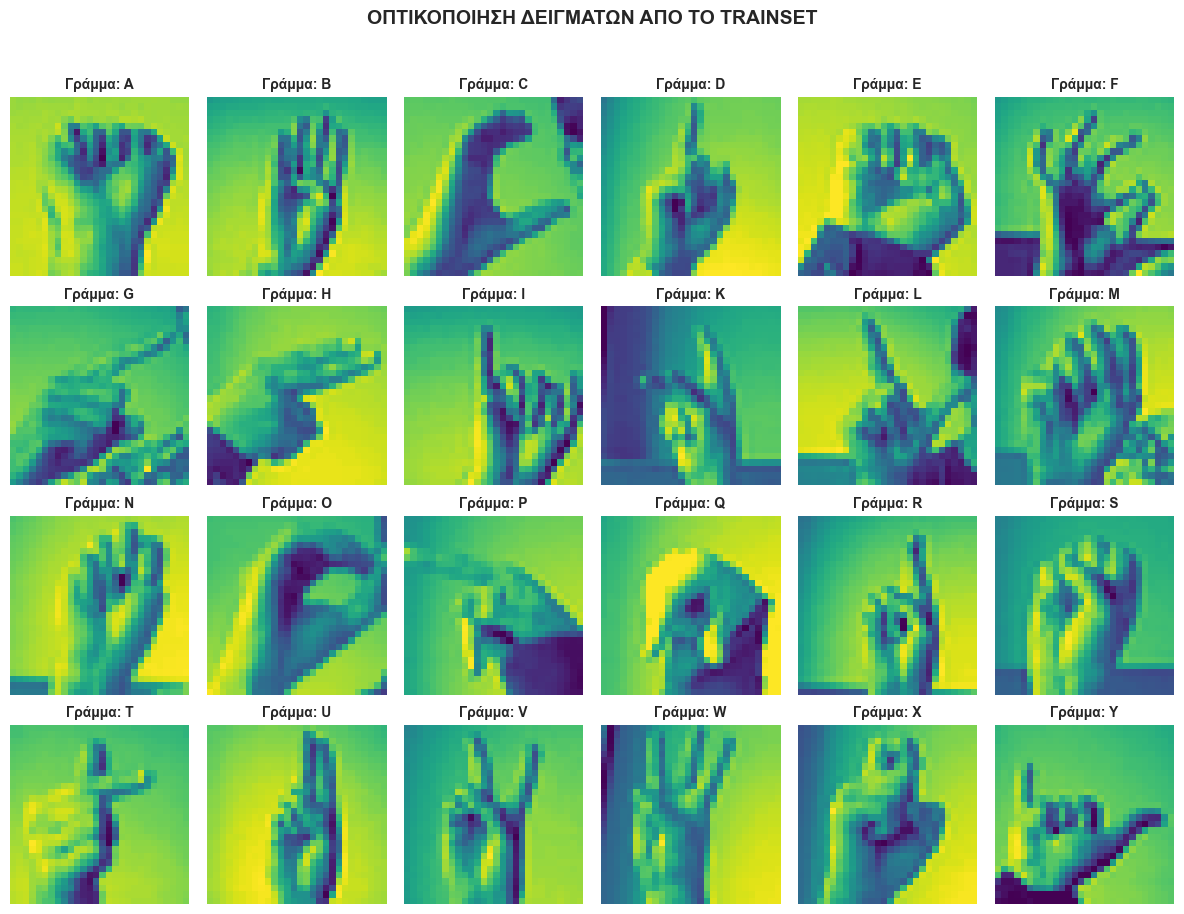

In [35]:
df_train = pd.read_csv('sign_mnist_train.csv').head(27455)

# 2. Ορισμός των γραμμάτων (A-Y, χωρίς το J)
letters = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 
           'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
fig, axes = plt.subplots(4, 6, figsize=(12, 9))
axes = axes.flatten()
unique_labels = sorted(df_train['label'].unique())

for i, label in enumerate(unique_labels):
    # Παίρνουμε την πρώτη γραμμή που αντιστοιχεί στο συγκεκριμένο γράμμα
    sample_row = df_train[df_train['label'] == label].iloc[0, 1:].values
    
    img = sample_row.reshape(28, 28)
    axes[i].imshow(img, cmap='viridis')
    axes[i].set_title(f"Γράμμα: {letters[i]}", fontsize=10, fontweight='bold')
    axes[i].axis('off')

fig.suptitle('ΟΠΤΙΚΟΠΟΙΗΣΗ ΔΕΙΓΜΑΤΩΝ ΑΠΟ ΤΟ TRAINSET', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

#### **ΕΞΕΤΑΣΗ ΚΑΤΑΝΟΜΗΣ ΚΑΤΗΓΟΡΙΩΝ**


C:\Users\user\AppData\Local\Temp\ipykernel_20884\1349039968.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


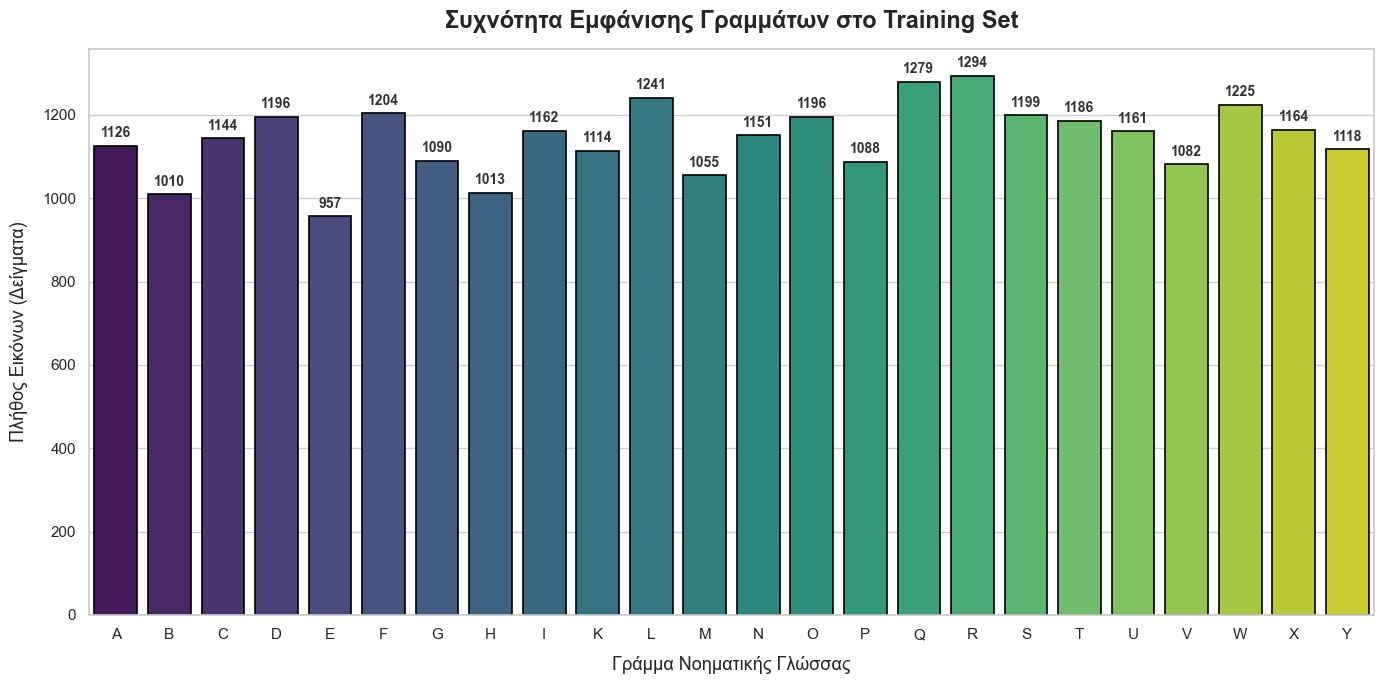

In [36]:
class_counts = df['label'].value_counts().sort_index()

letters = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 
           'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']

# 2. Στήσιμο του γραφήματος
# Χρησιμοποιούμε theme για πιο καθαρό background
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 7))

# Δημιουργία του barplot μέσω Seaborn για χρωματισμό
sns.barplot(
    x=letters, 
    y=class_counts.values, 
    palette="viridis",
    edgecolor="black",
    linewidth=1.2,
    ax=ax
)
# 3. Προσθήκη ετικετών (νούμερα) πάνω από τις μπάρες
for i in range(24):
    ax.bar_label(ax.containers[i], padding=4, fontsize=10, color='#333333', fontweight='bold')

# 4. Μορφοποίηση τίτλων και αξόνων
ax.set_title("Συχνότητα Εμφάνισης Γραμμάτων στο Training Set", fontsize=17, fontweight='bold', pad=15)
ax.set_xlabel("Γράμμα Νοηματικής Γλώσσας", fontsize=13, labelpad=10)
ax.set_ylabel("Πλήθος Εικόνων (Δείγματα)", fontsize=13, labelpad=10)

plt.tight_layout()
plt.show()

#### **Φόρτωση του Train Set και κανονικοποίηση pixel values**


In [3]:
df = pd.read_csv("sign_mnist_train.csv")
df = df.iloc[:27455, :]

X = df.drop('label', axis=1).values
display(X)
Y = df["label"].values

X = X / 255
display(X)

# Διαχωρισμός 80% training και 20% validation 
X_train, X_val, Y_train, Y_val = train_test_split(
    X, Y, 
    test_size=0.20, 
    random_state=42,
    stratify=Y 
)
train_size = X_train.shape[0]
val_size = X_val.shape[0]

print("- Training set size:", train_size)
print("- Validation set size:", val_size)

array([[107, 118, 127, ..., 204, 203, 202],
       [155, 157, 156, ..., 103, 135, 149],
       [187, 188, 188, ..., 195, 194, 195],
       ...,
       [174, 174, 174, ..., 202, 200, 200],
       [177, 181, 184, ...,  64,  87,  93],
       [179, 180, 180, ..., 205, 209, 215]], shape=(27455, 784))

array([[0.41960784, 0.4627451 , 0.49803922, ..., 0.8       , 0.79607843,
        0.79215686],
       [0.60784314, 0.61568627, 0.61176471, ..., 0.40392157, 0.52941176,
        0.58431373],
       [0.73333333, 0.7372549 , 0.7372549 , ..., 0.76470588, 0.76078431,
        0.76470588],
       ...,
       [0.68235294, 0.68235294, 0.68235294, ..., 0.79215686, 0.78431373,
        0.78431373],
       [0.69411765, 0.70980392, 0.72156863, ..., 0.25098039, 0.34117647,
        0.36470588],
       [0.70196078, 0.70588235, 0.70588235, ..., 0.80392157, 0.81960784,
        0.84313725]], shape=(27455, 784))

- Training set size: 21964
- Validation set size: 5491


#### **Φόρτωση του Test Set και κανονικοποίηση**

In [4]:
df_test = pd.read_csv("sign_mnist_test.csv")

X_test = df_test.drop('label', axis=1).values / 255
Y_test = df_test["label"].values

print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

X_test shape: (7172, 784)
Y_test shape: (7172,)


#### **kNN MODEL**

In [9]:
valResults=[]
testResults=[]
metrics = ['euclidean', 'manhattan', 'cosine']
neighbors = [1,3,5,7,11]

for m in metrics:
    for k in neighbors:
        start = time.time()
        knn = KNeighborsClassifier(n_neighbors=k, metric =m)
        knn.fit(X_train, Y_train)
        end = time.time()
        duration = end - start 

        predictions = knn.predict(X_val)
        accuracy = knn.score(X_val, Y_val)
        f1 = f1_score(Y_val, predictions, average = "macro")

        print(f"Training time for {m} with k={k}: {duration:.4f} seconds")
        valResults.append({'Metric': m, 'K': k, 'Accuracy': accuracy, 'F1': f1})
        
        predictions = knn.predict(X_test)
        accuracy = knn.score(X_test, Y_test)
        f1 = f1_score(Y_test, predictions, average = "macro")
        testResults.append({'Metric': m, 'K': k, 'Accuracy': accuracy, 'F1': f1})
        
        
print("Valdation Results")
valresults_df = pd.DataFrame(valResults)
print(valresults_df)
print("Test Results")
testresults_df = pd.DataFrame(testResults)
print(testresults_df)


Training time for euclidean with k=1: 0.0291 seconds
Training time for euclidean with k=3: 0.0237 seconds
Training time for euclidean with k=5: 0.0244 seconds
Training time for euclidean with k=7: 0.0271 seconds
Training time for euclidean with k=11: 0.0263 seconds
Training time for manhattan with k=1: 0.0262 seconds
Training time for manhattan with k=3: 0.0247 seconds
Training time for manhattan with k=5: 0.0304 seconds
Training time for manhattan with k=7: 0.0253 seconds
Training time for manhattan with k=11: 0.0242 seconds
Training time for cosine with k=1: 0.0265 seconds
Training time for cosine with k=3: 0.0247 seconds
Training time for cosine with k=5: 0.0241 seconds
Training time for cosine with k=7: 0.0258 seconds
Training time for cosine with k=11: 0.0254 seconds
Valdation Results
       Metric   K  Accuracy        F1
0   euclidean   1  0.998725  0.998727
1   euclidean   3  0.997997  0.997985
2   euclidean   5  0.997086  0.997065
3   euclidean   7  0.994719  0.994722
4   eucli

#### **SVM MODEL**

In [6]:
# Προετοιμασία για Cosine Kernel (L2 Normalization)
scaler = Normalizer()
X_train_normalized = scaler.fit_transform(X_train)
X_val_normalized = scaler.transform(X_val)

svm_testResults = []
svm_valResults = []
C_values = [0.1, 1, 10]
gamma_values = [0.1, 1, 10]

print("Ξεκινάει η μαζική εκπαίδευση SVM. Παρακαλώ περιμένετε...\n")

# --- 1. LINEAR KERNEL (Χρήση LinearSVC για 10x ταχύτητα) ---
for c in C_values:
    start_time = time.time()
    # dual=False προτείνεται όταν τα δείγματα (27k) > χαρακτηριστικά (784)
    model = LinearSVC(C=c, dual=False, random_state=42) 
    model.fit(X_train, Y_train)
    duration = time.time() - start_time
    
    predictions = model.predict(X_val)
    acc = accuracy_score(Y_val, predictions)
    f1 = f1_score(Y_val, predictions, average='macro')
    print(f"Training time for Linear (C={c}): {duration:.1f} seconds")
    svm_valResults.append({'Kernel': 'linear', 'C': c, 'Gamma': '-', 'Accuracy': acc, 'F1': f1})
    
    predictions = model.predict(X_test)
    acc = accuracy_score(Y_test, predictions)
    f1 = f1_score(Y_test, predictions, average='macro')
    svm_testResults.append({'Kernel': 'linear', 'C': c, 'Gamma': '-', 'Accuracy': acc, 'F1': f1})
    

# --- 2. COSINE KERNEL (Επίσης LinearSVC αλλά στα L2-normalized δεδομένα) ---
for c in C_values:
    start_time = time.time()
    model = LinearSVC(C=c, dual=False, random_state=42)
    model.fit(X_train_normalized, Y_train)
    duration = time.time() - start_time
    
    predictions = model.predict(X_val_normalized)
    acc = accuracy_score(Y_val, predictions)
    f1 = f1_score(Y_val, predictions, average='macro')
    print(f"Training time for Cosine (C={c}): {duration:.1f} seconds")
    svm_valResults.append({'Kernel': 'cosine', 'C': c, 'Gamma': '-', 'Accuracy': acc, 'F1': f1})
    
    predictions = model.predict(X_test)
    acc = accuracy_score(Y_test, predictions)
    f1 = f1_score(Y_test, predictions, average='macro')
    svm_testResults.append({'Kernel': 'cosine', 'C': c, 'Gamma': '-', 'Accuracy': acc, 'F1': f1})

# --- 3. RBF KERNEL (Ο κλασικός SVC με μεγάλη cache RAM) ---
for c in C_values:
    for g in gamma_values:
        start_time = time.time()
        # cache_size=2000 για ταχύτητα. Αν ο υπολογιστής σου κολλήσει, κάντο 1000.
        model = SVC(kernel='rbf', C=c, gamma=g, cache_size=2000, random_state=42)
        model.fit(X_train, Y_train)
        duration = time.time() - start_time
        
        predictions = model.predict(X_val)
        acc = accuracy_score(Y_val, predictions)
        f1 = f1_score(Y_val, predictions, average='macro')
        print(f"Training time for RBF (C={c}, gamma={g}): {duration:.1f} seconds")
        svm_valResults.append({'Kernel': 'rbf', 'C': c, 'Gamma': g, 'Accuracy': acc, 'F1': f1})
        
        predictions = model.predict(X_test)
        acc = accuracy_score(Y_test, predictions)
        f1 = f1_score(Y_test, predictions, average='macro')
        svm_testResults.append({'Kernel': 'rbf', 'C': c, 'Gamma': g, 'Accuracy': acc, 'F1': f1})

# --- Εμφάνιση Τελικών Αποτελεσμάτων ---
print("\n--- Validation Results ---")
svm_df = pd.DataFrame(svm_valResults)
print(svm_df.to_string(index=False))
print("\n--- Test Results ---")
svm_test_df = pd.DataFrame(svm_testResults)
print(svm_test_df.to_string(index=False))

Ξεκινάει η μαζική εκπαίδευση SVM. Παρακαλώ περιμένετε...

Training time for Linear (C=0.1): 68.0 seconds
Training time for Linear (C=1): 88.6 seconds
Training time for Linear (C=10): 99.1 seconds
Training time for Cosine (C=0.1): 47.8 seconds
Training time for Cosine (C=1): 55.9 seconds
Training time for Cosine (C=10): 62.8 seconds
Training time for RBF (C=0.1, gamma=0.1): 293.3 seconds
Training time for RBF (C=0.1, gamma=1): 515.1 seconds
Training time for RBF (C=0.1, gamma=10): 533.8 seconds
Training time for RBF (C=1, gamma=0.1): 121.9 seconds
Training time for RBF (C=1, gamma=1): 488.9 seconds
Training time for RBF (C=1, gamma=10): 563.0 seconds
Training time for RBF (C=10, gamma=0.1): 125.9 seconds
Training time for RBF (C=10, gamma=1): 492.1 seconds
Training time for RBF (C=10, gamma=10): 541.4 seconds

--- Validation Results ---
Kernel    C Gamma  Accuracy       F1
linear  0.1     -  0.999089 0.999113
linear  1.0     -  1.000000 1.000000
linear 10.0     -  1.000000 1.000000
cosi

#### **DESICION TREE MODEL**

In [ ]:
valResults = []
testResults = []
criterion = ['gini', 'entropy']
max_depth = [10, 20, 50, None]
min_samples_per_leaf = [1, 4, 10]

for c in criterion:
    for depth in max_depth:
        for leaf in min_samples_per_leaf:
            start_time = time.time()
            dtc = DecisionTreeClassifier(criterion=c, max_depth=depth, min_samples_leaf=leaf, random_state=42)
            dtc.fit(X_train, Y_train)
            end_time = time.time()
            elapsed = end_time - start_time

            predictions = dtc.predict(X_val)
            acc = accuracy_score(Y_val, predictions)
            f1 = f1_score(Y_val, predictions, average='macro')
            print(f"Training time for Decision Tree (criterion={c}, max_depth={depth}, min_samples_leaf={leaf}): {elapsed:.1f} seconds")
            valResults.append({'Criterion': c, 'Max Depth': depth, 'Min Samples Leaf': leaf, 'Accuracy': acc, 'F1': f1, 'Time (s)': round(elapsed, 1)})
            
            predictions = dtc.predict(X_test)
            acc = accuracy_score(Y_test, predictions)
            f1 = f1_score(Y_test, predictions, average='macro')
            testResults.append({'Criterion': c, 'Max Depth': depth, 'Min Samples Leaf': leaf, 'Accuracy': acc, 'F1': f1})
            

# --- Εμφάνιση Τελικών Αποτελεσμάτων ---
print("\n--- Validation Results ---")
dt_df = pd.DataFrame(valResults)
print(dt_df.to_string(index=False))
print("\n--- Test Results ---")
dt_test_df = pd.DataFrame(testResults)
print(dt_test_df.to_string(index=False))


Done with: criterion=gini, max_depth=10, min_samples_leaf=1 ολοκληρώθηκε σε 10.9 δευτ. -> Acc: 0.5864
Done with: criterion=gini, max_depth=10, min_samples_leaf=1 ολοκληρώθηκε σε 10.9 δευτ. -> Acc: 0.3508
Done with: criterion=gini, max_depth=10, min_samples_leaf=4 ολοκληρώθηκε σε 10.7 δευτ. -> Acc: 0.5820
Done with: criterion=gini, max_depth=10, min_samples_leaf=4 ολοκληρώθηκε σε 10.7 δευτ. -> Acc: 0.3528
Done with: criterion=gini, max_depth=10, min_samples_leaf=10 ολοκληρώθηκε σε 10.6 δευτ. -> Acc: 0.5742
Done with: criterion=gini, max_depth=10, min_samples_leaf=10 ολοκληρώθηκε σε 10.6 δευτ. -> Acc: 0.3532
Done with: criterion=gini, max_depth=20, min_samples_leaf=1 ολοκληρώθηκε σε 15.3 δευτ. -> Acc: 0.8610
Done with: criterion=gini, max_depth=20, min_samples_leaf=1 ολοκληρώθηκε σε 15.3 δευτ. -> Acc: 0.4236
Done with: criterion=gini, max_depth=20, min_samples_leaf=4 ολοκληρώθηκε σε 14.6 δευτ. -> Acc: 0.8345
Done with: criterion=gini, max_depth=20, min_samples_leaf=4 ολοκληρώθηκε σε 14.6

#### **RANDOM FOREST MODEL**

In [8]:
valResults = []
testResults = []
number_of_trees = [10, 50, 100, 200] 
max_depth = [3, 10, 20, None] 


# 2. Εξετάζουμε τους συνδυασμούς (Nested Loop)
for n in number_of_trees:
    for d in max_depth:
        start = time.time()
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=42)
        rf.fit(X_train, Y_train)
        end = time.time()
        elapsed = end - start

        # Πρόβλεψη και Αξιολόγηση
        predictions = rf.predict(X_val)
        acc = accuracy_score(Y_val, predictions)
        f1 = f1_score(Y_val, predictions, average='macro')
        print(f"Training time for Random Forest (Trees={n}, Max Depth={d}): {elapsed:.1f} seconds")
        valResults.append({'Trees': n, 'Max Depth': d, 'Accuracy': acc, 'F1': f1})
        
        
        predictions = rf.predict(X_test)
        acc = accuracy_score(Y_test, predictions)
        f1 = f1_score(Y_test, predictions, average='macro')
        testResults.append({'Trees': n, 'Max Depth': d, 'Accuracy': acc, 'F1': f1})
        
        
print("\n--- Validation Results ---")
rf_val_df = pd.DataFrame(valResults)
print(rf_val_df.to_string(index=False))
print("\n--- Test Results ---")
rf_test_df = pd.DataFrame(testResults)
print(rf_test_df.to_string(index=False))

Training time for Random Forest (Trees=10, Max Depth=3): 0.8 seconds
Training time for Random Forest (Trees=10, Max Depth=10): 2.8 seconds
Training time for Random Forest (Trees=10, Max Depth=20): 4.1 seconds
Training time for Random Forest (Trees=10, Max Depth=None): 4.0 seconds
Training time for Random Forest (Trees=50, Max Depth=3): 3.9 seconds
Training time for Random Forest (Trees=50, Max Depth=10): 13.8 seconds
Training time for Random Forest (Trees=50, Max Depth=20): 19.7 seconds
Training time for Random Forest (Trees=50, Max Depth=None): 20.3 seconds
Training time for Random Forest (Trees=100, Max Depth=3): 7.7 seconds
Training time for Random Forest (Trees=100, Max Depth=10): 29.3 seconds
Training time for Random Forest (Trees=100, Max Depth=20): 39.7 seconds
Training time for Random Forest (Trees=100, Max Depth=None): 39.7 seconds
Training time for Random Forest (Trees=200, Max Depth=3): 14.9 seconds
Training time for Random Forest (Trees=200, Max Depth=10): 56.2 seconds
Trai

#### **ADABOOST MODEL**

In [ ]:
valResults = []
testResults = []
estimators_list = [50, 100, 150]
learning_rates = [0.1, 1, 5]

for n in estimators_list:
    for lr in learning_rates:
        start = time.time()
        ada = AdaBoostClassifier(n_estimators=n, learning_rate=lr, random_state=42)
        ada.fit(X_train, Y_train)
        end = time.time()
        elapsed = end - start

        predictions = ada.predict(X_val)
        accuracy = accuracy_score(Y_val, predictions)
        f1 = f1_score(Y_val, predictions, average='macro')
        print(f"Training time for AdaBoost (Estimators={n}, Learning Rate={lr}): {elapsed:.1f} seconds")
        valResults.append({'Estimators': n, 'Learning Rate': lr, 'Accuracy': accuracy, 'F1': f1})
        
        predictions = ada.predict(X_test)
        accuracy = accuracy_score(Y_test, predictions)
        f1 = f1_score(Y_test, predictions, average='macro')
        testResults.append({'Estimators': n, 'Learning Rate': lr, 'Accuracy': accuracy, 'F1': f1})
        
print("\n--- Validation Results ---")
ada_val_df = pd.DataFrame(valResults)
print(ada_val_df.to_string(index=False))
print("\n--- Test Results ---")
ada_test_df = pd.DataFrame(testResults)
print(ada_test_df.to_string(index=False))

Training time for AdaBoost (Estimators=50, Learning Rate=1): 56.7 seconds
Training time for AdaBoost (Estimators=50, Learning Rate=5): 56.9 seconds
Training time for AdaBoost (Estimators=50, Learning Rate=10): 56.0 seconds
Training time for AdaBoost (Estimators=100, Learning Rate=1): 113.3 seconds
Training time for AdaBoost (Estimators=100, Learning Rate=5): 113.2 seconds
Training time for AdaBoost (Estimators=100, Learning Rate=10): 112.7 seconds
Training time for AdaBoost (Estimators=150, Learning Rate=1): 166.9 seconds
Training time for AdaBoost (Estimators=150, Learning Rate=5): 168.2 seconds
Training time for AdaBoost (Estimators=150, Learning Rate=10): 167.7 seconds

--- Validation Results ---
 Estimators  Learning Rate  Accuracy       F1
         50              1  0.192133 0.171662
         50              5  0.067565 0.033799
         50             10  0.105992 0.070043
        100              1  0.261883 0.246863
        100              5  0.157348 0.121430
        100    

#### **FNN MODEL**


In [ ]:
from sklearn.neural_network import MLPClassifier
valresults1= []
valresults2 = [] 
valresults3 =[]
testresults1= []
testresults2 = []
testresults3 = []

model = MLPClassifier(max_iter=500, hidden_layer_sizes=(128,), random_state=42)
start = time.time()
model.fit(X_train, Y_train)
end = time.time()
duration = end - start 

predictions = model.predict(X_val)
accuracy = accuracy_score(Y_val, predictions)
f1 = f1_score(Y_val, predictions, average='macro')
print(f"Training time for MLPClassifier (1 hidden layer): {duration:.4f} seconds")
valresults1.append({'Hidden Layers': 1, 'Accuracy': accuracy, 'F1': f1})


predictions = model.predict(X_test)
accuracy = accuracy_score(Y_test, predictions)
f1 = f1_score(Y_test, predictions, average='macro')
testresults1.append({'Hidden Layers': 1, 'Accuracy': accuracy, 'F1': f1})

print("1 Hidden Layer")
print("Validation Set")
df_val1 = pd.DataFrame(valresults1)
print(df_val1.to_string(index=False))
print("Test Set Results")
df_test1 = pd.DataFrame(testresults1)
print(df_test1.to_string(index=False))

#2 hidden layers
model = MLPClassifier(max_iter=500, hidden_layer_sizes=(128,128), random_state=42)
start = time.time()
model.fit(X_train, Y_train)
end = time.time()
duration = end - start 
predictions = model.predict(X_val)
accuracy = accuracy_score(Y_val, predictions)
f1 = f1_score(Y_val, predictions, average='macro')
print(f"Training time for MLPClassifier (2 hidden layers): {duration:.4f} seconds")
valresults2.append({'Hidden Layers': 2, 'Accuracy': accuracy, 'F1': f1})

predictions = model.predict(X_test)
accuracy = accuracy_score(Y_test, predictions)
f1 = f1_score(Y_test, predictions, average='macro')
testresults2.append({'Hidden Layers': 2, 'Accuracy': accuracy, 'F1': f1})

print("2 Hidden Layers")
print("Validation Set")
df_val2 = pd.DataFrame(valresults2)
print(df_val2.to_string(index=False))
print("Test Set Results")
df_test2 = pd.DataFrame(testresults2)
print(df_test2.to_string(index=False))

#3 hidden layers
model = MLPClassifier(max_iter=500, hidden_layer_sizes=(128,128,128), random_state=42)
start = time.time()
model.fit(X_train, Y_train)
end = time.time()
duration = end - start 
predictions = model.predict(X_val)
accuracy = accuracy_score(Y_val, predictions)
f1 = f1_score(Y_val, predictions, average='macro')
print(f"Training time for MLPClassifier (3 hidden layers): {duration:.4f} seconds")
valresults3.append({'Hidden Layers': 3, 'Accuracy': accuracy, 'F1': f1})

predictions = model.predict(X_test)
accuracy = accuracy_score(Y_test, predictions)
f1 = f1_score(Y_test, predictions, average='macro')
testresults3.append({'Hidden Layers': 3, 'Accuracy': accuracy, 'F1': f1})

print("3 Hidden Layers")
print("Validation Set")
df_val3 = pd.DataFrame(valresults3)
print(df_val3.to_string(index=False))
print("Test Set Results")
df_test3 = pd.DataFrame(testresults3)
print(df_test3.to_string(index=False))


MLPClassifier ολοκληρώθηκε σε 56.3 δευτ. -> Accuracy: 1.0000, F1 Score: 1.0000
Training time for MLPClassifier (1 hidden layer): 56.2719 seconds
1 Hidden Layer
Validation Set
 Hidden Layers  Accuracy  F1
             1       1.0 1.0
Test Set Results
 Hidden Layers  Accuracy      F1
             1  0.718489 0.69145
Training time for MLPClassifier (2 hidden layers): 36.4941 seconds
2 Hidden Layers
Validation Set
 Hidden Layers  Accuracy  F1
             2       1.0 1.0
Test Set Results
 Hidden Layers  Accuracy       F1
             2  0.751534 0.726717
Training time for MLPClassifier (3 hidden layers): 37.9686 seconds
3 Hidden Layers
Validation Set
 Hidden Layers  Accuracy  F1
             3       1.0 1.0
Test Set Results
 Hidden Layers  Accuracy      F1
             3  0.775098 0.74821


In [5]:


# 1. Προετοιμασία Δεδομένων για CNN (Αλλαγή σχήματος σε 28x28x1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

def train_and_evaluate_cnn(experiment_name, num_layers, k_size, use_maxpool=True):
    model = models.Sequential()
    model.add(layers.Input(shape=(28, 28, 1)))

    for i in range(num_layers):
        # Χρησιμοποιούμε padding='same' για να μην "μηδενιστεί" η εικόνα στα πολλά layers
        model.add(layers.Conv2D(32, (k_size, k_size), activation='relu', padding='same'))
        if use_maxpool:
            model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(25, activation='softmax'))

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    start = time.time()
    model.fit(X_train_cnn, Y_train, epochs=20, batch_size=128, 
              validation_data=(X_val_cnn, Y_val), verbose=0)
    train_time = time.time() - start

    # Metrics για Validation Set
    val_preds = np.argmax(model.predict(X_val_cnn, verbose=0), axis=1)
    val_acc = accuracy_score(Y_val, val_preds)
    val_f1 = f1_score(Y_val, val_preds, average='macro', zero_division=0)

    # Metrics για Test Set
    test_preds = np.argmax(model.predict(X_test_cnn, verbose=0), axis=1)
    test_acc = accuracy_score(Y_test, test_preds)
    test_f1 = f1_score(Y_test, test_preds, average='macro', zero_division=0)

    return {
        "Scenario": experiment_name,
        "Kernel": f"{k_size}x{k_size}",
        "Pooling": "Yes" if use_maxpool else "No",
        "Val Acc (%)": round(val_acc * 100, 2),
        "Val F1": round(val_f1, 4),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Test F1": round(test_f1, 4),
        "Training Time (s)": round(train_time, 1)
    }

# --- Λίστα Πειραμάτων ---
# Ορίζουμε τα σενάρια με βάση τις απαιτήσεις της εκφώνησης
all_results = []

# Σενάριο 1: 1 Layer με και χωρίς Max Pooling
for k in [3, 5, 7]:
    all_results.append(train_and_evaluate_cnn("1-Conv Layer", 1, k, use_maxpool=True))
    all_results.append(train_and_evaluate_cnn("1-Conv Layer", 1, k, use_maxpool=False))

# Σενάριο 2: 2 Layers (Δοκιμή μεσαίας αρχιτεκτονικής)
for k in [3, 5]:
    all_results.append(train_and_evaluate_cnn("2-Conv Layers", 2, k, use_maxpool=True))

# Σενάριο 3: 3 Layers (Βαθιά αρχιτεκτονική)
all_results.append(train_and_evaluate_cnn("3-Conv Layers", 3, 3, use_maxpool=True))

# --- Εμφάνιση Τελικού Πίνακα ---
cnn_df = pd.DataFrame(all_results)
print("\n--- Συγκεντρωτικά Αποτελέσματα CNN ---")
print(cnn_df.to_string(index=False))


--- Συγκεντρωτικά Αποτελέσματα CNN ---
     Scenario Kernel Pooling  Val Acc (%)  Val F1  Test Acc (%)  Test F1  Training Time (s)
 1-Conv Layer    3x3     Yes       100.00  1.0000         85.28   0.8487               65.5
 1-Conv Layer    3x3      No       100.00  1.0000         74.58   0.7268              131.8
 1-Conv Layer    5x5     Yes       100.00  1.0000         87.67   0.8675               63.3
 1-Conv Layer    5x5      No        99.98  0.9998         77.47   0.7590              139.4
 1-Conv Layer    7x7     Yes        99.93  0.9993         88.02   0.8603               69.9
 1-Conv Layer    7x7      No       100.00  1.0000         81.33   0.8008              138.8
2-Conv Layers    3x3     Yes       100.00  1.0000         92.93   0.9196               67.3
2-Conv Layers    5x5     Yes       100.00  1.0000         90.23   0.8973               94.2
3-Conv Layers    3x3     Yes       100.00  1.0000         95.69   0.9530               70.9


In [5]:


# --- 1. Εκπαίδευση και Αποθήκευση του Καλύτερου Μοντέλου ---
best_rf_model = SVC(kernel='rbf', C=10, gamma=0.1, cache_size=2000, random_state=42)

print("Εκπαίδευση του τελικού μοντέλου...")
best_rf_model.fit(X_train, Y_train)

# Αποθήκευση του μοντέλου σε αρχείο .pkl
joblib.dump(best_rf_model, "best_model.pkl")
print("Το μοντέλο αποθηκεύτηκε επιτυχώς ως 'best_model.pkl'!")

# --- 2. Προετοιμασία για το Hidden Phrase Challenge ---

# Το λεξικό ακριβώς όπως δίνεται στην εκφώνηση
LABEL_TO_LETTER = {
    0:'A', 1:'B', 2:'C', 3:'D', 4:'E', 5:'F', 6:'G', 7:'H', 8:'I', 9:'K',
    10:'L', 11:'M', 12:'N', 13:'O', 14:'P', 15:'Q', 16:'R', 17:'S',
    18:'T', 19:'U', 20:'V', 21:'W', 22:'X', 23:'Y'
}

def predict_letters(model, test_images):
  
    if len(test_images.shape) > 2:
        test_images = test_images.reshape(test_images.shape[0], -1)
        
    # Πρόβλεψη των labels (αριθμοί 0-24)
    if test_images.max() > 1.0:  # Αν είναι raw pixels (0-255)
        test_images = test_images / 255.0
    predicted_labels = model.predict(test_images)
    
    # Μετατροπή των αριθμών σε γράμματα
    phrase_letters = []
    for label in predicted_labels:
        letter = LABEL_TO_LETTER[label]
        phrase_letters.append(letter)
        
    # Η join ενώνει όλα τα γράμματα της λίστας σε ένα ενιαίο κείμενο.
    secret_phrase = "".join(phrase_letters)
    
    return secret_phrase


Εκπαίδευση του τελικού μοντέλου...
Το μοντέλο αποθηκεύτηκε επιτυχώς ως 'best_model.pkl'!
